In [3]:
import pandas as pd
import numpy as np

# 2. Text Processing & Regular Expressions (ETL Phase)
import re
import ast

# 3. Machine Learning & Data Mining (Optimization & Clustering Phase)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans

# 4. Network Graph Visualization (DDI / Redundancy Phase)
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns

# 5. System Utilities & Formatting
import warnings
warnings.filterwarnings('ignore')

# Set pandas to show full text in columns (critical for reading long chemical compositions)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
df = pd.read_csv('data/medicines.csv') 

print(f"Total Records: {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}")
print("\nColumns:", df.columns.tolist())

df.head(2)

Total Records: 253973
Total Columns: 9

Columns: ['id', 'name', 'price(₹)', 'Is_discontinued', 'manufacturer_name', 'type', 'pack_size_label', 'short_composition1', 'short_composition2']


,id,name,price(₹),Is_discontinued,manufacturer_name,type,pack_size_label,short_composition1,short_composition2
0,1,Augmentin 625 Duo Tablet,223.42,False,Glaxo SmithKline Pharmaceuticals Ltd,allopathy,strip of 10 tablets,Amoxycillin (500mg),Clavulanic Acid (125mg)
1,2,Azithral 500 Tablet,132.36,False,Alembic Pharmaceuticals Ltd,allopathy,strip of 5 tablets,Azithromycin (500mg),NaN


In [6]:
print("Starting ETL Transformation...")

# 1. Filter out discontinued medicines (We only want available drugs for our optimizer)
df_clean = df[df['Is_discontinued'] == False].copy()

# 2. Regex Function: Extract pure chemical name and convert to UPPERCASE
def extract_pure_salt(text):
    if pd.isna(text) or str(text).strip() == "":
        return ""
    # re.sub finds the parentheses and everything inside \(.*?\) and replaces it with nothing ''
    pure_salt = re.sub(r'\(.*?\)', '', str(text)).strip()
    return pure_salt.upper()

# 3. Apply the transformation to the composition columns
df_clean['salt_1'] = df_clean['short_composition1'].apply(extract_pure_salt)
df_clean['salt_2'] = df_clean['short_composition2'].apply(extract_pure_salt)

# 4. Create a unified "Chemical Signature" (The core logic for our Redundancy detection)
def create_signature(row):
    salts = [row['salt_1'], row['salt_2']]
    # Keep only non-empty salts
    valid_salts = [s for s in salts if s != ""]
    
    # DATA MINING TRICK: Sort them alphabetically! 
    # This ensures "Paracetamol + Caffeine" matches "Caffeine + Paracetamol"
    valid_salts.sort() 
    
    return " + ".join(valid_salts)

df_clean['chemical_signature'] = df_clean.apply(create_signature, axis=1)

# 5. Rename the price column to remove special characters for easier coding later
df_clean.rename(columns={'price(₹)': 'price'}, inplace=True)

# Keep only the columns we actually need for the model to save memory
columns_to_keep = ['name', 'price', 'manufacturer_name', 'chemical_signature']
df_final = df_clean[columns_to_keep]

# Drop rows that have no chemical signature (bad data)
df_final = df_final[df_final['chemical_signature'] != ""]

print(f"Cleaned Dataset Shape: {df_final.shape}")
df_final.head()

Starting ETL Transformation...
Cleaned Dataset Shape: (246068, 4)


,name,price,manufacturer_name,chemical_signature
0,Augmentin 625 Duo Tablet,223.42,Glaxo SmithKline Pharmaceuticals Ltd,AMOXYCILLIN + CLAVULANIC ACID
1,Azithral 500 Tablet,132.36,Alembic Pharmaceuticals Ltd,AZITHROMYCIN
2,Ascoril LS Syrup,118.00,Glenmark Pharmaceuticals Ltd,AMBROXOL + LEVOSALBUTAMOL
3,Allegra 120mg Tablet,218.81,Sanofi India Ltd,FEXOFENADINE
4,Avil 25 Tablet,10.96,Sanofi India Ltd,PHENIRAMINE


In [9]:
df_final.tail(6)

,name,price,manufacturer_name,chemical_signature
253967,Zef CV 200mg/125mg Tablet,260.0,ZRS Labs,CEFIXIME + CLAVULANIC ACID
253968,Ziyapod 100mg Oral Suspension,62.3,Ziyana Lifesciences Pvt Ltd,CEFPODOXIME PROXETIL
253969,Zemhart 30mg Tablet,54.0,Leeford Healthcare Ltd,DILTIAZEM
253970,Zivex 25mg Tablet,57.0,Euro Organics,HYDROXYZINE
253971,ZI Fast 500mg Injection,152.0,Burgeon Health Series Private Limited,AZITHROMYCIN
253972,Zyvocol 1% Dusting Powder,110.0,GBK Healthcare,CLOTRIMAZOLE


In [10]:
df.isnull().sum()

id                         0
name                       0
price(₹)                   0
Is_discontinued            0
manufacturer_name          0
type                       0
pack_size_label            0
short_composition1         0
short_composition2    141802
dtype: int64

In [ ]:
print("Finalizing Numerical Preprocessing & Outlier Handling...")

# 1. Drop rows where critical ML features (price or manufacturer) are missing
df_final.dropna(subset=['price', 'manufacturer_name'], inplace=True)

# 2. Remove exact duplicates (common in scraped Kaggle datasets)
df_final.drop_duplicates(inplace=True)

# 3. Handle Price Outliers using IQR 
Q1 = df_final['price'].quantile(0.25)
Q3 = df_final['price'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

df_final['price'] = np.where(df_final['price'] > upper_bound, upper_bound, df_final['price'])

# Reset index for a clean slate
df_final.reset_index(drop=True, inplace=True)

print(f"Final ML-Ready Dataset Shape: {df_final.shape}")
print(f"Total Missing Values Now:\n{df_final.isnull().sum()}")

Finalizing Numerical Preprocessing & Outlier Handling...
Final ML-Ready Dataset Shape: (245983, 4)
Total Missing Values Now:
name                  0
price                 0
manufacturer_name     0
chemical_signature    0
dtype: int64


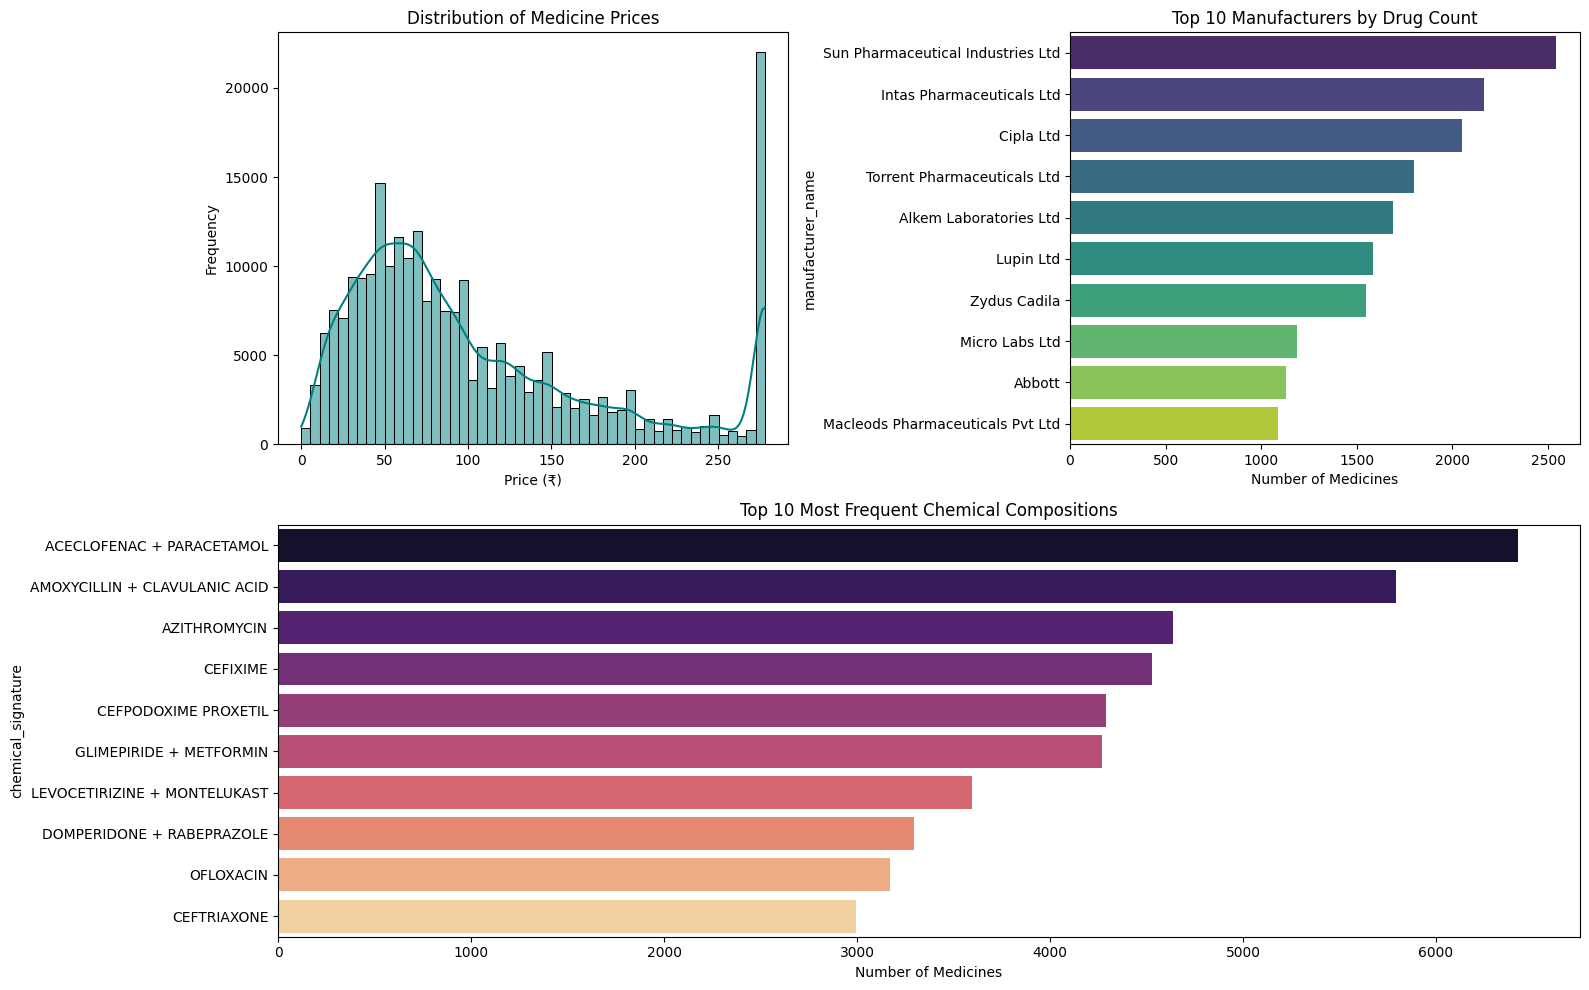

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 10))

plt.subplot(2, 2, 1)
sns.histplot(df_final['price'], bins=50, kde=True, color='teal')
plt.title('Distribution of Medicine Prices')
plt.xlabel('Price (₹)')
plt.ylabel('Frequency')

plt.subplot(2, 2, 2)
top_mfg = df_final['manufacturer_name'].value_counts().head(10)
sns.barplot(x=top_mfg.values, y=top_mfg.index, palette='viridis')
plt.title('Top 10 Manufacturers by Drug Count')
plt.xlabel('Number of Medicines')

plt.subplot(2, 2, (3, 4))
top_salts = df_final['chemical_signature'].value_counts().head(10)
sns.barplot(x=top_salts.values, y=top_salts.index, palette='magma')
plt.title('Top 10 Most Frequent Chemical Compositions')
plt.xlabel('Number of Medicines')

plt.tight_layout()
plt.show()

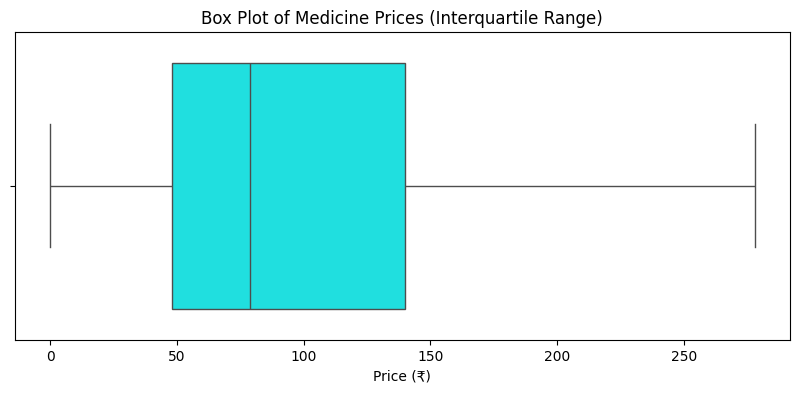

In [13]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df_final['price'], color='cyan')

plt.title('Box Plot of Medicine Prices (Interquartile Range)')
plt.xlabel('Price (₹)')
plt.show()

In [18]:
import os

# Check if the notebook is running inside the 'notebook' folder or the root folder
if os.path.basename(os.getcwd()) == 'notebook':
    artifacts_dir = os.path.join('..', 'artifacts')
else:
    artifacts_dir = 'artifacts'

# Create the folder at the root level if it doesn't exist
os.makedirs(artifacts_dir, exist_ok=True)

# Save the file
save_path = os.path.join(artifacts_dir, 'clean_medicines.csv')
df_final.to_csv(save_path, index=False)

print("Data preprocessing complete and saved successfully.")

Data preprocessing complete and saved successfully.
